In [2]:
%pip install -q "qiskit[visualization]" qiskit

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


Enter your IBM Quantum API key:  ········
Enter your IBM Quantum instance (CRN or instance name):  crn:v1:bluemix:public:quantum-computing:us-east:a/00b3915f8e7243f7a01812846e4b3fa3:c5c6654f-1782-4b1a-9ec3-6b7cea9475b3::


qiskit_runtime_service._discover_account:WARNING:2026-10-12 16:00:41,882: Loading account with the given token. A saved account will not be used.


Connected to IBM Quantum successfully!
Selected backend: ibm_kingston
Circuit A: One X gate


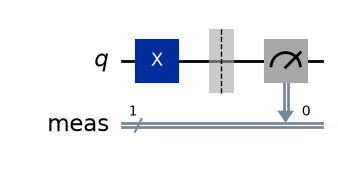

Circuit B: Two X gates


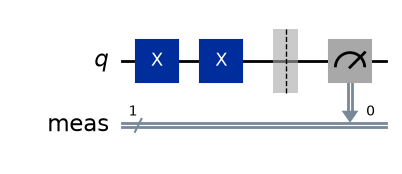

Circuit C: One H gate


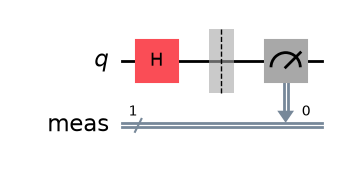


PREDICTIONS
Circuit A: 1 -> approximately 100 counts of 1
Circuit B: 0 -> approximately 100 counts of 0
Circuit C: approximately 50% 0 and 50% 1


C:\Users\pravallika malluri\AppData\Local\Temp\ipykernel_22752\3927249416.py:77: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)



Job ID: db6bdr4lf4us73c53a80

ACTUAL RESULTS
Circuit A: {'1': 76, '0': 24}
Circuit B: {'1': 53, '0': 47}
Circuit C: {'0': 45, '1': 55}

COMPARISON
Circuit A: The X gate flips |0> to |1>.
Circuit B: Two X gates return the qubit to |0>.
Circuit C: The H gate creates a superposition.
Circuit C may produce both 0 and 1 outcomes.
Small deviations can occur because of hardware noise.


In [1]:

# IBM Quantum - Qiskit Fall Fest 2026
# Challenge 1: Predict the Output

%pip install -q "qiskit[visualization]" qiskit-ibm-runtime qiskit-aer

from getpass import getpass
from qiskit import QuantumCircuit
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# STEP 1: Connect to IBM Quantum
api_key = getpass("Enter your IBM Quantum API key: ")
instance = input("Enter your IBM Quantum instance (CRN or instance name): ").strip()

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=instance
)

print("Connected to IBM Quantum successfully!")

# STEP 2: Select an available real quantum computer
backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=1
)

print("Selected backend:", backend.name)

# STEP 3: Create Circuit A - One X gate
qc_a = QuantumCircuit(1)
qc_a.x(0)
qc_a.measure_all()

# STEP 4: Create Circuit B - Two X gates
qc_b = QuantumCircuit(1)
qc_b.x(0)
qc_b.x(0)
qc_b.measure_all()

# STEP 5: Create Circuit C - One H gate
qc_c = QuantumCircuit(1)
qc_c.h(0)
qc_c.measure_all()

# STEP 6: Display the circuits
print("Circuit A: One X gate")
display(qc_a.draw("mpl"))

print("Circuit B: Two X gates")
display(qc_b.draw("mpl"))

print("Circuit C: One H gate")
display(qc_c.draw("mpl"))

# STEP 7: Predictions before execution
print("\nPREDICTIONS")
print("Circuit A: 1 -> approximately 100 counts of 1")
print("Circuit B: 0 -> approximately 100 counts of 0")
print("Circuit C: approximately 50% 0 and 50% 1")

# STEP 8: Transpile circuits for the selected backend
circuits = [qc_a, qc_b, qc_c]

pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1
)

isa_circuits = pm.run(circuits)

# STEP 9: Execute all three circuits for 100 shots each
sampler = Sampler(mode=backend)

job = sampler.run(isa_circuits, shots=100)
result = job.result()

print("\nJob ID:", job.job_id())

# STEP 10: Extract and display actual measurement results
counts_a = result[0].data.meas.get_counts()
counts_b = result[1].data.meas.get_counts()
counts_c = result[2].data.meas.get_counts()

print("\nACTUAL RESULTS")
print("Circuit A:", counts_a)
print("Circuit B:", counts_b)
print("Circuit C:", counts_c)

# STEP 11: Plot histograms
plot_histogram(
    [counts_a, counts_b, counts_c],
    legend=["Circuit A: X", "Circuit B: X + X", "Circuit C: H"],
    title="Challenge 1: Measurement Results (100 Shots)"
)
plt.show()

# STEP 12: Compare predictions with actual results
print("\nCOMPARISON")
print("Circuit A: The X gate flips |0> to |1>.")
print("Circuit B: Two X gates return the qubit to |0>.")
print("Circuit C: The H gate creates a superposition.")
print("Circuit C may produce both 0 and 1 outcomes.")
print("Small deviations can occur because of hardware noise.")
